# Modelos de Regresión y Clasificación

> Problema de Aprendizaje Supervisado

Se basa en construir un modelo $\hat{Y} = \Phi(X)$, que generalmente se simplifica a un modelo simple y paramétrico:

$$
\hat{y} = \phi(x, \beta)
$$

Lo que se busca es encontrar el comportamiento de las respuestas observadas $y$, a partir de las características informativas $x$, pero reguladas por parámetros fijos que aprendan y consoliden el modelo como un modelo fijo de predicción:

$$
y \approx \hat{y}
$$

Conjunto de datos -> $X$, $Y$

* $X$ - Características informativas
* $Y$ - Respuestas de predicción

## Modelo constante

> $\beta_0$ es la respuesta constante a todas las posibles respuestas (*bias*)

$$
\hat{y} = \beta_0
$$

In [2]:
import numpy
import pandas

from matplotlib import pyplot
import seaborn

In [3]:
titanic = pandas.read_csv("../conjuntos/titanic.csv")

titanic

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


> $X \in \mathbb{R}^k$, $y \in \mathbb{R}$

In [ ]:
# X -> Un espacio numérico
# x1 = ...

# y -> Un espacio numérico
y = titanic["Survived"] # Numérico / Discreto 2-clases

In [ ]:
pandas.concat([
    y.value_counts(), # Soportes
    y.value_counts(normalize=True), # Proporción / Probabilidad
], axis=1)

,count,proportion
Survived,,
0,549,0.616162
1,342,0.383838


In [25]:
b0 = 0.4 # Creencia inicial o el prior

yp = b0 * numpy.ones_like(y)

pandas.DataFrame({
    "y": y,
    "yp": yp,
})

,y,yp
0,0,0.4
1,1,0.4
2,1,0.4
3,1,0.4
4,0,0.4
...,...,...
886,0,0.4
887,1,0.4
888,0,0.4
889,1,0.4


In [26]:
e = y - yp # Vector de error (y - vector de 891 | yp - vector de 891)

# e = y - yp | yp = y - e

# Entropía cruzada binaria (métrica de los error)
L = -(y * numpy.log(y - e) + (1 - y) * numpy.log(1 - y + e)).mean()

L

np.float64(0.666458695565084)

In [50]:
# Optimizador aleatorio

b0 = 0.5 # creencia inicial

for epoca in range(1_000):
    yp = b0 * numpy.ones_like(y)
    e = y - yp
    L = -(y * numpy.log(y - e) + (1 - y) * numpy.log(1 - y + e)).mean()

    # b0 alternativa (creencia nueva)
    b0_alt = b0 + numpy.random.normal(0, 0.1) # La b0 alternativa está cerca de b0, pero aleatoriamente arriba o abajo
    yp_alt = b0_alt * numpy.ones_like(y)
    e_alt = y - yp_alt
    L_alt = -(y * numpy.log(numpy.clip(y - e_alt, 0, 1)) + (1 - y) * numpy.log(numpy.clip(1 - y + e_alt, 0, 1))).mean()

    if L >= L_alt:
        print(f"{epoca:3d} | L={L:.4f} | La={L_alt:.4f} | b0={b0:.4f} | b0a={b0_alt:.4f}")
        b0 = b0_alt

  0 | L=0.6931 | La=0.6878 | b0=0.5000 | b0a=0.4879
  1 | L=0.6878 | La=0.6678 | b0=0.4879 | b0a=0.3545
  5 | L=0.6678 | La=0.6675 | b0=0.3545 | b0a=0.4117
  6 | L=0.6675 | La=0.6674 | b0=0.4117 | b0a=0.3579
 13 | L=0.6674 | La=0.6663 | b0=0.3579 | b0a=0.3696
 15 | L=0.6663 | La=0.6663 | b0=0.3696 | b0a=0.3970
 29 | L=0.6663 | La=0.6662 | b0=0.3970 | b0a=0.3721
 31 | L=0.6662 | La=0.6660 | b0=0.3721 | b0a=0.3888
 49 | L=0.6660 | La=0.6659 | b0=0.3888 | b0a=0.3864
 83 | L=0.6659 | La=0.6659 | b0=0.3864 | b0a=0.3822
 88 | L=0.6659 | La=0.6659 | b0=0.3822 | b0a=0.3826
112 | L=0.6659 | La=0.6659 | b0=0.3826 | b0a=0.3830
185 | L=0.6659 | La=0.6659 | b0=0.3830 | b0a=0.3839
283 | L=0.6659 | La=0.6659 | b0=0.3839 | b0a=0.3838


In [51]:
b0

0.38380035369646337

## Modelo Lineal (1ra neurona de estudio)

Predictor lineal

$$
z = \beta_0 + \beta_1 \cdot x_1 + \beta_2 \cdot x_2 + \ldots + \beta_k \cdot x_k
$$

Modelo lineal

$$
\hat{y} = z
$$

Ecuaciones normales

$$
X \beta = y
$$

$$
X^T X \beta = X^T y
$$
$$
\beta = (X^T X)^{-1} X^T y
$$

Cuidado: Si la matriz $X^T X$ tiene determinante cercano a 0, la inversa no existe

In [ ]:
titanic["Age"].median() # La edad ideal para el 50% de la población (la edad central)

np.float64(28.0)

In [ ]:
x1 = titanic["Age"].fillna(titanic["Age"].median()) # Peor imputación válida 
# (Imputación de la mediana -> reemplazar los nulos por la edad mediana)
x1[x1 < 1] = x1[x1 < 1] * 100 # Limpieza de datos (sustituir todas las edad incorrectas menores a 1 por 100)

x2 = numpy.log(1 + titanic["Fare"]) # Transformación Box-Cox por logaritmo -> reduce el ruido de la escala
# Limpieza de atípicos sin pérdida de información
#x2.plot.box(vert=False)

# Codificación One-Hot
x3 = (titanic["Pclass"] == 1).astype(int) # Dummy ser 1ra clase
x4 = (titanic["Pclass"] == 2).astype(int) # Dummy ser 2da clase
# x5 = (titanic["Pclass"] == 3).astype(int) # Dummy ser 3ra clase 
# !!! Multicolinealidad (esta variable se puede deducir linealmente de otras)
# x5 = 0.5 * (2 - x3) + 0.5 * (2 - x4) = 2 - 0.5 * x3 - 0.5 * x4 !!! combinación lineal 
# -> el determinante será cercano a 0 (ninguna o infinitas soluciones)

# Cubo de datos numérico -> Todos características son numéricas
# Espacio numérico de la información de las características
X = pandas.DataFrame([x1, x2, x3, x4], index=["x1", "x2", "x3", "x4"]).T

X.round(2)

,x1,x2,x3,x4
0,22.0,2.11,0.0,0.0
1,38.0,4.28,1.0,0.0
2,26.0,2.19,0.0,0.0
3,35.0,3.99,1.0,0.0
4,35.0,2.20,0.0,0.0
...,...,...,...,...
886,27.0,2.64,0.0,1.0
887,19.0,3.43,1.0,0.0
888,28.0,3.20,0.0,0.0
889,26.0,3.43,1.0,0.0


In [65]:
numpy.log(1 + 70)

np.float64(4.2626798770413155)

In [37]:
numpy.random.normal(0, 0.1)

-0.10018936246123622

### Modelo de aprendizaje supervisado ($X \rightarrow y$)

In [74]:
pandas.concat([X, y], axis=1)

,x1,x2,x3,x4,Survived
0,22.0,2.110213,0.0,0.0,0
1,38.0,4.280593,1.0,0.0,1
2,26.0,2.188856,0.0,0.0,1
3,35.0,3.990834,1.0,0.0,1
4,35.0,2.202765,0.0,0.0,0
...,...,...,...,...,...
886,27.0,2.639057,0.0,1.0,0
887,19.0,3.433987,1.0,0.0,1
888,28.0,3.196630,0.0,0.0,0
889,26.0,3.433987,1.0,0.0,1


In [80]:
b0 = 0 # bias inicial (creencia)
b1 = 1 # peso asociado a x1 inicial (creencia)
b2 = 1 # peso asociado a x2 inicial (creencia)
b3 = 1 # peso asociado a x3 inicial (creencia)
b4 = 1 # peso asociado a x4 inicial (creencia)

# Optimizador aleatorio
for epoca in range(10_000):

    # Modelo lineal (creencias originales)
    z = b0 + b1 * x1 + b2 * x2 + b3 * x3 + b4 * x4 # combina cada vector xj de información con un peso de información
    yp = z # Modelo lineal -> vector de predicción

    e = y - yp # Vector error entre la respuesta real y la respuesta de predicción
    mse = (e ** 2).mean() # Mean Square Error -> Error Cuadrático Promedio
    L = mse
    
    # Modelo lineal alternativo (creencias alternativas)
    b0_alt = b0 + numpy.random.normal(0, 0.1)
    b1_alt = b1 + numpy.random.normal(0, 0.1)
    b2_alt = b2 + numpy.random.normal(0, 0.1)
    b3_alt = b3 + numpy.random.normal(0, 0.1)
    b4_alt = b4 + numpy.random.normal(0, 0.1)

    z_alt = b0_alt + b1_alt * x1 + b2_alt * x2 + b3_alt * x3 + b4_alt * x4 # combina cada vector xj de información con un peso de información
    yp_alt = z_alt # Modelo lineal -> vector de predicción

    e_alt = y - yp_alt # Vector error entre la respuesta real y la respuesta de predicción
    mse_alt = (e_alt ** 2).mean() # Mean Square Error -> Error Cuadrático Promedio
    L_alt = mse_alt

    if L_alt < L:
        b0 = b0_alt
        b1 = b1_alt
        b2 = b2_alt
        b3 = b3_alt
        b4 = b4_alt

b0, b1, b2, b3, b4

(0.18524069073702695,
 -0.005948905287303866,
 0.0859556666911519,
 0.318694957321268,
 0.20144600954325087)

In [84]:
z = b0 + b1 * x1 + b2 * x2 + b3 * x3 + b4 * x4 # combina cada vector xj de información con un peso de información
yp = z

pandas.DataFrame([y, yp], index=["y", "yp"]).T

,y,yp
0,0.0,0.235750
1,1.0,0.645818
2,1.0,0.218714
3,1.0,0.638759
4,0.0,0.166369
...,...,...
886,0.0,0.452908
887,1.0,0.686077
888,0.0,0.293440
889,1.0,0.644435


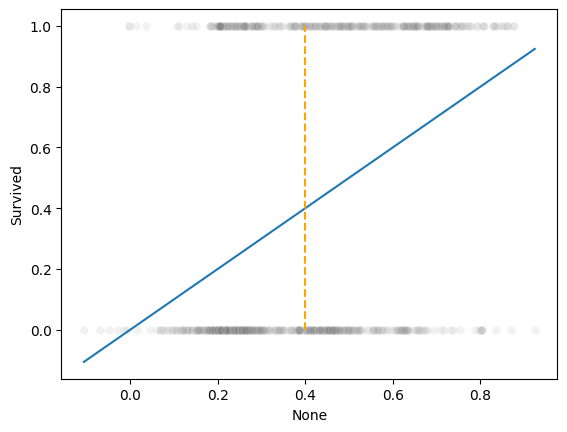

In [89]:
seaborn.scatterplot(x=z, y=y, color="gray", alpha=0.1)
seaborn.lineplot(x=z, y=yp)
pyplot.vlines(0.4, 0, 1, color="orange", linestyle="--")

In [105]:
umbral = 0.4 # El óptimo se encuentra mediante el módulo de Young u otras técnicas

M = pandas.DataFrame([y, yp >= umbral], index=["y", "yp"]).T.groupby(["y", "yp"]).size().unstack()

M

yp,0,1
y,,
0,379,170
1,130,212


In [121]:
tn, fp, fn, tp = M.values.flatten()

accuracy = (tn + tp) / (tn + fp + fn + tp) # exactitud
precision = tp / (fp + tp) # precisión
sensitivity = tp / (fn + tp) # recall -> sensibilidad
specificity = tn / (fp + tn) # especificidad
npv = tn / (fn + tn) # Negative-Predictive-Value -> valor negativo de predicción
f1 = 2 * (precision * sensitivity) / (precision + sensitivity) # F1-Score -> balance entre precisión y sensibilidad (predicción verdadera)

(pandas.DataFrame({
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Sensitivity": [sensitivity],
    "Specificity": [specificity],
    "NPV": [npv],
    "F1-Score": [f1],
}, index=["%"]).T * 100).round(1)

,%
Accuracy,66.3
Precision,55.5
Sensitivity,62.0
Specificity,69.0
NPV,74.5
F1-Score,58.6


## Modelo Logístico

- $y \in (-\infty, \infty)$ - Abierta -> Problema de Regresión
- $y \in [0, 1]$ - Cerrada -> Problema de Clasificación

Predictor lineal

$$
z = \beta_0 + \beta_1 \cdot x_1 + \beta_2 \cdot x_2 + \ldots + \beta_k \cdot x_k
$$

Modelo de predicción (Lineal $\phi(z) = z$ | Logístico $\phi(z) = \frac{e^z}{1 + e^z}$)

$$
\hat{y} = \sigma(z) = \frac{e^z}{1 + e^z} = \frac{1}{1 + e^{-z}}
$$

Text(0, 0.5, '$\\hat{y}$')

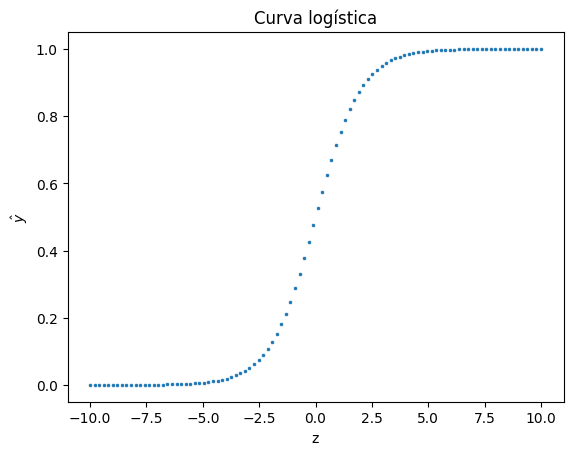

In [126]:
z = numpy.linspace(-10, 10, 100)

yp = numpy.exp(z) / (1 + numpy.exp(z))

seaborn.scatterplot(x=z, y=yp, marker=".")
pyplot.title("Curva logística")
pyplot.xlabel("z")
pyplot.ylabel("$\\hat{y}$")

In [ ]:
# expit | inversa del logit
def sigma(z):
    return numpy.exp(z) / (1 + numpy.exp(z))

In [128]:
b0 = 0 # bias inicial (creencia)
b1 = 1 # peso asociado a x1 inicial (creencia)
b2 = 1 # peso asociado a x2 inicial (creencia)
b3 = 1 # peso asociado a x3 inicial (creencia)
b4 = 1 # peso asociado a x4 inicial (creencia)

# Optimizador aleatorio
for epoca in range(10_000):

    # Modelo lineal (creencias originales)
    z = b0 + b1 * x1 + b2 * x2 + b3 * x3 + b4 * x4 # combina cada vector xj de información con un peso de información
    yp = sigma(z) # Modelo lineal -> vector de predicción

    e = y - yp # Vector error entre la respuesta real y la respuesta de predicción
    mse = (e ** 2).mean() # Mean Square Error -> Error Cuadrático Promedio
    L = mse
    
    # Modelo lineal alternativo (creencias alternativas)
    b0_alt = b0 + numpy.random.normal(0, 0.1)
    b1_alt = b1 + numpy.random.normal(0, 0.1)
    b2_alt = b2 + numpy.random.normal(0, 0.1)
    b3_alt = b3 + numpy.random.normal(0, 0.1)
    b4_alt = b4 + numpy.random.normal(0, 0.1)

    z_alt = b0_alt + b1_alt * x1 + b2_alt * x2 + b3_alt * x3 + b4_alt * x4 # combina cada vector xj de información con un peso de información
    yp_alt = sigma(z_alt) # Modelo lineal -> vector de predicción

    e_alt = y - yp_alt # Vector error entre la respuesta real y la respuesta de predicción
    mse_alt = (e_alt ** 2).mean() # Mean Square Error -> Error Cuadrático Promedio
    L_alt = mse_alt

    if L_alt < L:
        b0 = b0_alt
        b1 = b1_alt
        b2 = b2_alt
        b3 = b3_alt
        b4 = b4_alt

b0, b1, b2, b3, b4

(-1.4661213503064128,
 -0.022687104019496175,
 0.3684722308554925,
 1.3446914789677828,
 0.9876877624202984)

In [130]:
z = b0 + b1 * x1 + b2 * x2 + b3 * x3 + b4 * x4 # combina cada vector xj de información con un peso de información
yp = sigma(z)

pandas.DataFrame([y, yp], index=["y", "yp"]).T

,y,yp
0,0.0,0.233674
1,1.0,0.644223
2,1.0,0.222795
3,1.0,0.635303
4,0.0,0.190231
...,...,...
886,0.0,0.470393
887,1.0,0.671029
888,0.0,0.284247
889,1.0,0.635071


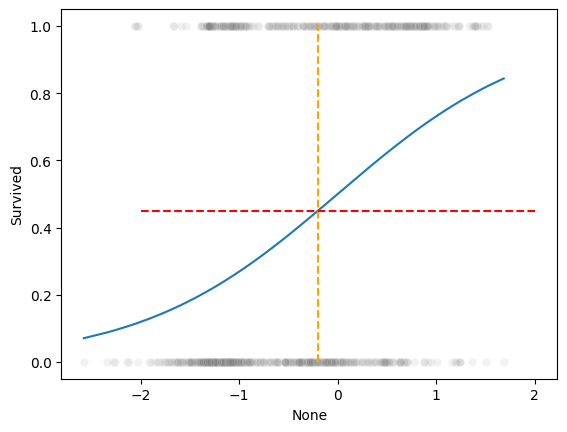

In [134]:
seaborn.scatterplot(x=z, y=y, color="gray", alpha=0.1)
seaborn.lineplot(x=z, y=yp)
pyplot.vlines(-0.2, 0, 1, color="orange", linestyle="--")
pyplot.hlines(0.45, -2, 2, color="red", linestyle="--")

In [135]:
umbral = 0.45 # El óptimo se encuentra mediante el módulo de Young u otras técnicas

M = pandas.DataFrame([y, yp >= umbral], index=["y", "yp"]).T.groupby(["y", "yp"]).size().unstack()

M

yp,0,1
y,,
0,425,124
1,149,193


In [136]:
tn, fp, fn, tp = M.values.flatten()

accuracy = (tn + tp) / (tn + fp + fn + tp) # exactitud
precision = tp / (fp + tp) # precisión
sensitivity = tp / (fn + tp) # recall -> sensibilidad
specificity = tn / (fp + tn) # especificidad
npv = tn / (fn + tn) # Negative-Predictive-Value -> valor negativo de predicción
f1 = 2 * (precision * sensitivity) / (precision + sensitivity) # F1-Score -> balance entre precisión y sensibilidad (predicción verdadera)

(pandas.DataFrame({
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Sensitivity": [sensitivity],
    "Specificity": [specificity],
    "NPV": [npv],
    "F1-Score": [f1],
}, index=["%"]).T * 100).round(1)

,%
Accuracy,69.4
Precision,60.9
Sensitivity,56.4
Specificity,77.4
NPV,74.0
F1-Score,58.6


## Neuronas

In [137]:
# ! pip install tensorflow keras

In [141]:
import keras

model = keras.Sequential([
    keras.Input(shape=(4,)),
    keras.layers.Dense(1, activation="sigmoid") # lineal -> problema de respueta abierta | sigmoid -> problema de respuesta cerrada
])

model.compile(
    optimizer="adam", # SGD -> Gradiente estocástico por descenso | ADAM -> Gradiente con momento adaptativo
    loss="binary_crossentropy", # lineal -> mse | sigmoid -> binary_crossentropy
    metrics=["accuracy"] # lineal -> mse, mae | sigmoid -> accuracy
)

print(model.summary())

history = model.fit(X, y, epochs=100)

history

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5 (20.00 B)

 Trainable params: 5 (20.00 B)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3963 - loss: 13.5032  
Epoch 2/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3867 - loss: 13.3461
Epoch 3/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3882 - loss: 12.7498
Epoch 4/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3747 - loss: 12.2721 
Epoch 5/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3902 - loss: 11.5182 
Epoch 6/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 997us/step - accuracy: 0.3882 - loss: 11.0765
Epoch 7/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.4002 - loss: 10.1056
Epoch 8/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 968us/step - accuracy: 0.3811 - loss: 9.9977
Epoch 9/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.3620 - loss: 9.6574
Epoch 10/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3996 - loss: 8.5378 
Epoch 11/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3916 - loss: 8.2465  
Epoch 12/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 